In [1]:
import os
import utils
import torch
import pickle
import numpy as np
import matplotlib.pyplot as plt

from torch import nn
from sklearn.metrics import ConfusionMatrixDisplay
from torch.utils.data import DataLoader, TensorDataset

# PARAMETRI

In [2]:
EPOCHS = 100
BATCH_SIZE = 128
LEARNING_RATE = 0.001
DEVICE = torch.accelerator.current_accelerator() if torch.accelerator.is_available() else torch.device('cpu')

print(f"DEVICE: {DEVICE}")

DEVICE: cuda


In [3]:
from datasets.datasets import load_IMDB

# DATASET: 50.000 recensioni di film (IMDB), 25.000 di training e 25.000 di test, metà positive e metà negative.
# Ogni recensione è una sequenza di indici di parole ordinate per frequenza (0 = padding, 1 = inizio, 2 = parola rara)
NUM_WORDS = 10000     # si tengono solo le parole più frequenti: le altre diventano 2
MAXLEN = 500          # le recensioni vengono troncate, o completate con zeri all'inizio, fino a MAXLEN parole

(x_train, y_train), (x_test, y_test) = load_IMDB(num_words=NUM_WORDS, maxlen=MAXLEN)
print(f"SHAPE: X_TRAIN = {x_train.shape}, Y_TRAIN = {y_train.shape}")
print(f"SHAPE: X_TEST = {x_test.shape}, Y_TEST = {y_test.shape}")
print(f"RECENSIONI POSITIVE (train): {y_train.mean():.0%}\n")
print(x_train[0])

train_dataset = TensorDataset(torch.tensor(x_train), torch.tensor(y_train))
test_dataset = TensorDataset(torch.tensor(x_test), torch.tensor(y_test))
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

SHAPE: X_TRAIN = (25000, 500), Y_TRAIN = (25000,)
SHAPE: X_TEST = (25000, 500), Y_TEST = (25000,)
RECENSIONI POSITIVE (train): 50%

[   0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0 

# MODELLO

## Blocco di self-attention

![Blocco di self-attention](imgs/attention_block.png)
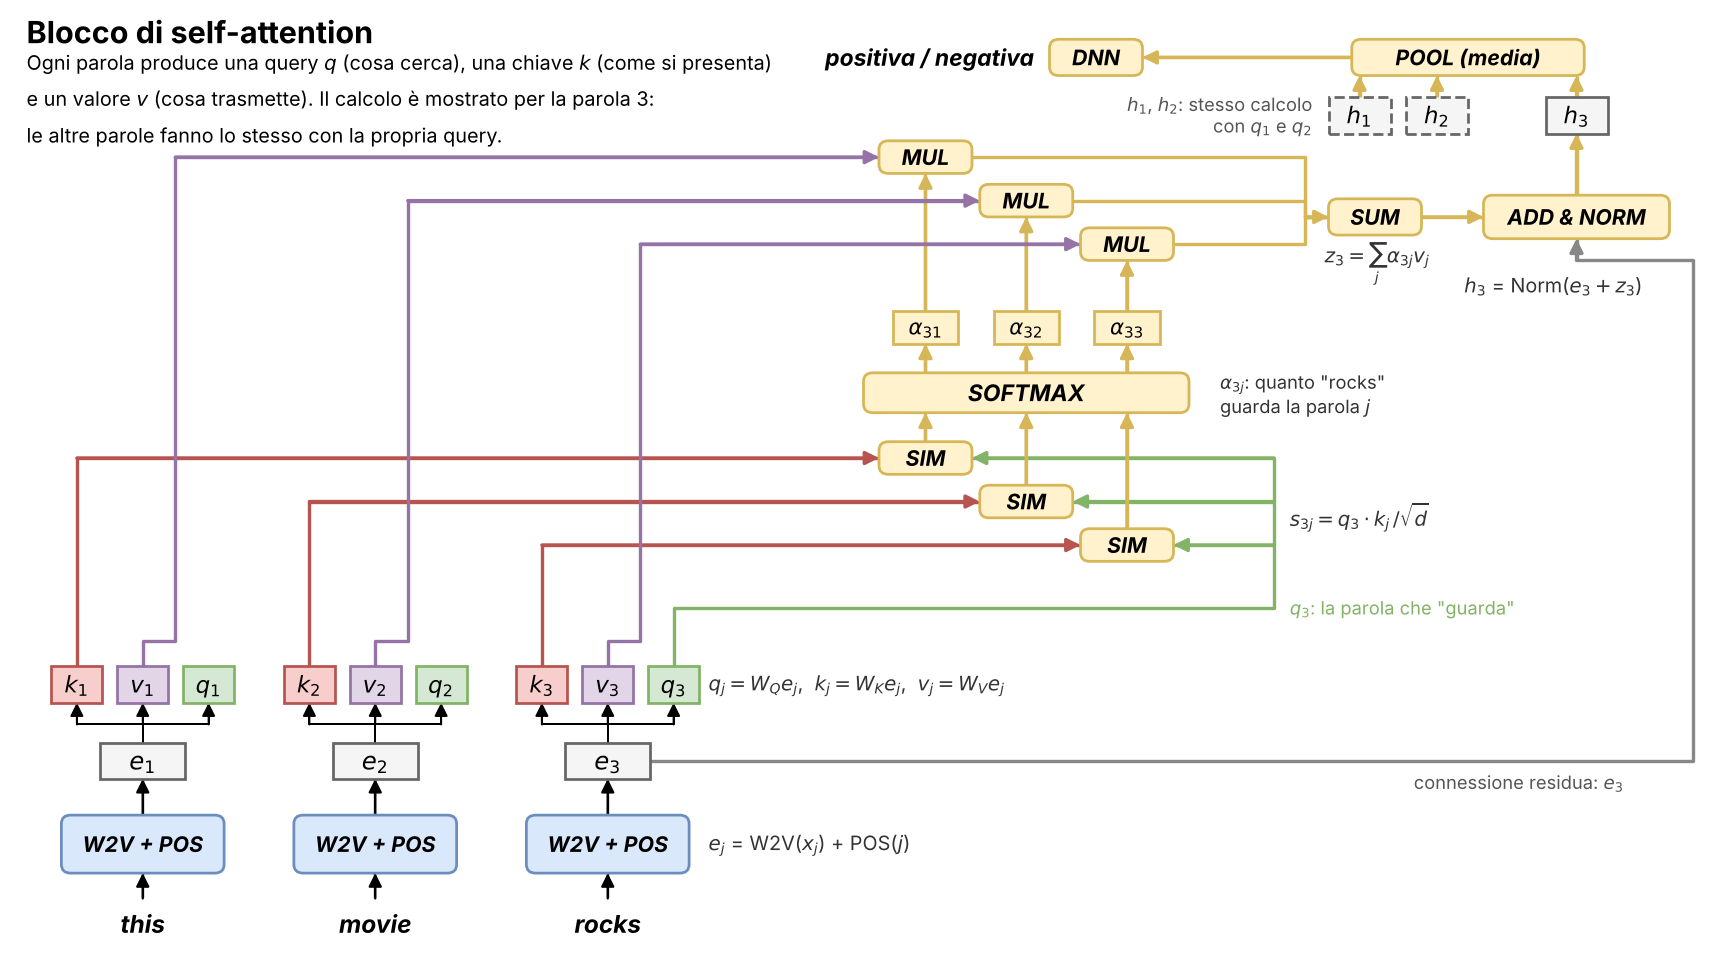

In [4]:
#Parametri del modello
EMBEDDING_DIM = 32                # dimensione d di e, q, k, v e h
NUM_CLASSES = 2                   # negativa, positiva

In [5]:
class AttentionClassifier(nn.Module):
    def __init__(self, num_words, embedding_dim, maxlen, num_classes):
        super().__init__()
        self.embedding = nn.Embedding(num_words, embedding_dim)            # Word Embedding: ogni parola -> vettore da embedding_dim valori
        self.position = nn.Embedding(maxlen, embedding_dim)                # POS: un vettore per ogni posizione nella recensione
        self.query = nn.Linear(embedding_dim, embedding_dim, bias=False)   # W_Q
        self.key = nn.Linear(embedding_dim, embedding_dim, bias=False)     # W_K
        self.value = nn.Linear(embedding_dim, embedding_dim, bias=False)   # W_V
        self.norm = nn.LayerNorm(embedding_dim)                            # NORM
        self.fc = nn.Linear(embedding_dim, num_classes)                    # DNN

    def forward(self, x):                                       # (B, 500) indici delle parole
        pad = x == 0                                            # (B, 500) posizioni di padding
        positions = torch.arange(x.shape[1], device=x.device)
        e = self.embedding(x) + self.position(positions)        # Word Embedding + Position Embedding: (B, 500, D)
        q, k, v = self.query(e), self.key(e), self.value(e)     # (B, 500, D) ciascuno
        scores = q @ k.transpose(1, 2) / e.shape[-1] ** 0.5     # SIM: s_ij = q_i · k_j / sqrt(d) -> (B, 500, 500)
        scores = scores.masked_fill(pad.unsqueeze(1), -float('inf'))   # nessuna parola guarda il padding
        alpha = torch.softmax(scores, dim=-1)                   # SOFTMAX su j: (B, 500, 500)
        z = alpha @ v                                           # MUL e SUM: z_i = sum_j alpha_ij v_j -> (B, 500, D)
        h = self.norm(e + z)                                    # ADD & NORM: connessione residua e normalizzazione
        keep = (~pad).unsqueeze(-1).float()                     # (B, 500, 1): 1 sulle parole vere, 0 sul padding
        pooled = (h * keep).sum(dim=1) / keep.sum(dim=1)        # POOL: media sulle parole vere -> (B, D)
        return self.fc(pooled)                                  # DNN: logit (B, NUM_CLASSES)

torch.manual_seed(7)
model = AttentionClassifier(NUM_WORDS, EMBEDDING_DIM, MAXLEN, NUM_CLASSES).to(DEVICE)

# RMSprop mantiene una media mobile dei quadrati dei gradienti e divide il gradiente per la sua radice.
optimizer = torch.optim.RMSprop(model.parameters(), lr=LEARNING_RATE, alpha=0.9, eps=1e-7)
# Due logit + CrossEntropyLoss equivalgono a un logit + sigmoide + binary cross-entropy, e l'accuracy si calcola con argmax
criterion = nn.CrossEntropyLoss()

print(model)
print(f"Parametri: {sum(p.numel() for p in model.parameters())}")

AttentionClassifier(
  (embedding): Embedding(10000, 32)
  (position): Embedding(500, 32)
  (query): Linear(in_features=32, out_features=32, bias=False)
  (key): Linear(in_features=32, out_features=32, bias=False)
  (value): Linear(in_features=32, out_features=32, bias=False)
  (norm): LayerNorm((32,), eps=1e-05, elementwise_affine=True, bias=True)
  (fc): Linear(in_features=32, out_features=2, bias=True)
)
Parametri: 339202


# ADDESTRAMENTO

  0%|          | 0/5 [00:00<?, ?it/s]

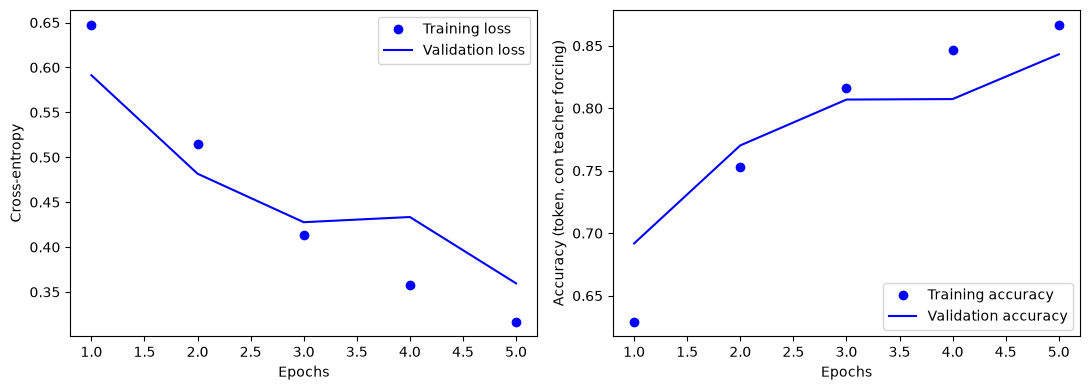

In [6]:
os.makedirs('histories', exist_ok=True)
filename = "text_classifier_attention"

hist_path = f'histories/{filename}.hist'
weights_path = f'histories/{filename}.pt'
if os.path.isfile(hist_path) and os.path.isfile(weights_path):
    with open(hist_path, 'rb') as hist_file:
        history = pickle.load(hist_file)
    model.load_state_dict(torch.load(weights_path, map_location=DEVICE))
else:
    history = utils.train(model, optimizer, criterion, train_loader, test_loader, 5, DEVICE)
    with open(hist_path, 'wb') as hist_file:
        pickle.dump(history, hist_file)
    torch.save(model.state_dict(), weights_path)

utils.hist_plot(history)

# VALUTAZIONE

accuracy train = 0.879   accuracy test = 0.843


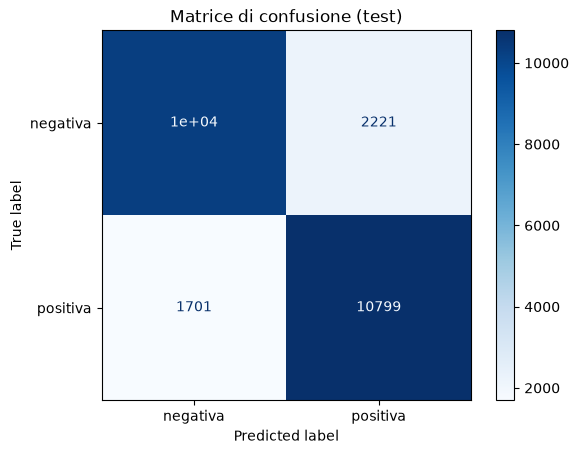

In [7]:
def predict(model, dataset, batch_size=256):
    # a blocchi: ogni recensione ha una matrice di attenzione 500 x 500, tutte insieme non entrano in memoria
    model.eval()
    preds = []
    with torch.no_grad():
        for x, _ in DataLoader(dataset, batch_size=batch_size, shuffle=False):
            preds.append(model(x.to(DEVICE)).argmax(dim=1).cpu())
    return torch.cat(preds).numpy()

y_train_pred = predict(model, train_dataset)
y_test_pred = predict(model, test_dataset)
print(f"accuracy train = {np.mean(y_train_pred == y_train):.3f}   accuracy test = {np.mean(y_test_pred == y_test):.3f}")

ConfusionMatrixDisplay.from_predictions(y_test, y_test_pred, display_labels=['negativa', 'positiva'], cmap='Blues')
plt.title(f'Matrice di confusione (test)')
plt.show()